<a href="https://colab.research.google.com/github/paolorch/CEIA-Vision-Computadora-I-TP2/blob/main/TP2_VC1_ROJAS_CHACON.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Universidad de Buenos Aires - FIUBA - LSE**
### **Visión por computadora I - TP2**

5to bimestre 2026

### Docente: **Maxim Dorogov**

### Alumno: **André Paolo Rojas Chacón**
Nro. SIU: **a2713**

### Introducción

Este trabajo práctico aborda la detección de máximo enfoque en un video mediante el análisis de sus componentes en el dominio de la frecuencia. Se implementa una métrica de enfoque basada en la transformada de Fourier y se evalúa su comportamiento a lo largo del video, tanto sobre el fotograma completo como sobre una región central.

Finalmente, se aplica la técnica Unsharp Masking para analizar la posibilidad de ampliar la región de enfoque y evaluar los resultados obtenidos.

### Consignas del trabajo práctico

**Parte 1 – Detección de máximo enfoque**

1. Implementar la métrica propuesta en el paper *Image Sharpness Measure for Blurred Images in Frequency Domain*.
2. Aplicar la métrica sobre todos los fotogramas del video `focus_video.mov`.
3. Repetir el experimento sobre una ROI centrada que represente el 5 % o el 10 % del área total del frame.
4. Graficar la evolución de la métrica en ambos experimentos y detectar automáticamente las regiones de máximo enfoque.

**Parte 2 – Ampliación de la región de enfoque (puntos extra)**

1. Aplicar Unsharp Masking para ampliar la región de enfoque del video.
2. Comparar los resultados antes y después del procesamiento.

## 1. Detección de máximo enfoque

### 1.1 Carga y visualización del video

Se carga el video proporcionado para el trabajo práctico mediante OpenCV, se obtienen sus características principales y se visualizan fotogramas representativos para realizar una primera inspección del material a procesar.

Resolución: 640 x 360 píxeles
FPS: 29.97
Total de fotogramas: 171
Duración: 5.71 segundos
Fotogramas leídos: 171


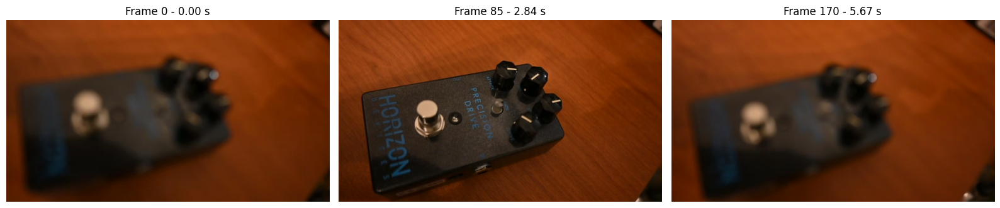

In [3]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Carga del video
ruta = 'focus_video.mov'
captura = cv.VideoCapture(ruta)

if not captura.isOpened():
    raise ValueError('No se pudo abrir el video')

# Características del video
ancho = int(captura.get(cv.CAP_PROP_FRAME_WIDTH))
alto = int(captura.get(cv.CAP_PROP_FRAME_HEIGHT))
fps = captura.get(cv.CAP_PROP_FPS)
total_frames = int(captura.get(cv.CAP_PROP_FRAME_COUNT))
duracion = total_frames / fps

print(f'Resolución: {ancho} x {alto} píxeles')
print(f'FPS: {fps:.2f}')
print(f'Total de fotogramas: {total_frames}')
print(f'Duración: {duracion:.2f} segundos')

# Selección de fotogramas representativos
indices = [0, total_frames // 2, total_frames - 1]
frames_muestra = {}

i = 0

while True:
    ret, frame = captura.read()

    if not ret:
        break

    if i in indices:
        frames_muestra[i] = frame.copy()

    i += 1

captura.release()

print(f'Fotogramas leídos: {i}')

# Visualización de los fotogramas seleccionados
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (indice, frame) in zip(axes, frames_muestra.items()):
    ax.imshow(cv.cvtColor(frame, cv.COLOR_BGR2RGB))
    ax.set_title(f'Frame {indice} - {indice / fps:.2f} s')
    ax.axis('off')

plt.tight_layout()
plt.show()


**Observaciones:**

- El video tiene una resolución de 640 × 360 píxeles, una duración de 5.71 segundos y un total de 171 fotogramas, los cuales fueron leídos correctamente.
- Se seleccionaron tres fotogramas correspondientes al inicio, la mitad y el final del video para observar los cambios de enfoque sin determinar previamente la región de máximo enfoque.
- Los fotogramas inicial y final presentan un desenfoque considerable, mientras que en el fotograma intermedio se distinguen con mayor claridad los bordes, las letras y las texturas del objeto.
- Estas diferencias sugieren cambios en las componentes de alta frecuencia de la imagen, los cuales se analizarán mediante la transformada de Fourier.

### 1.2 Análisis en el dominio de la frecuencia

Se aplica la transformada de Fourier bidimensional sobre los fotogramas seleccionados en la sección anterior para analizar la relación entre el enfoque y las componentes de frecuencia de cada imagen.

Se utiliza una escala logarítmica para visualizar los espectros y una misma escala de colores para facilitar su comparación.

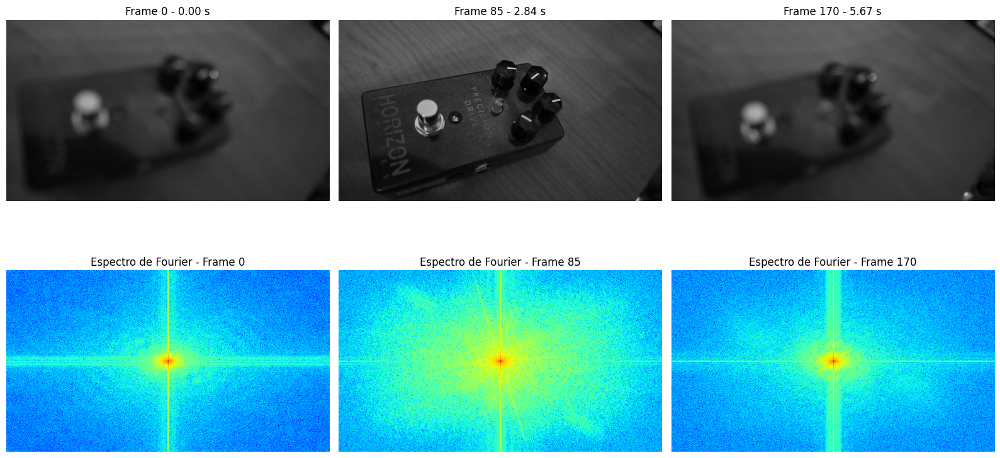

In [4]:

espectros = {}
frames_grises = {}

# Transformada de Fourier de los fotogramas seleccionados
for indice, frame in frames_muestra.items():

    # Conversión a escala de grises
    gris = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    frames_grises[indice] = gris

    # Transformada de Fourier y centrado del espectro
    fft = np.fft.fft2(gris)
    fft_centrada = np.fft.fftshift(fft)

    # Magnitud del espectro en escala logarítmica
    magnitud = np.abs(fft_centrada)
    espectros[indice] = 20 * np.log(magnitud + 1)

# Escala común para comparar los espectros
vmin = min(np.min(espectro) for espectro in espectros.values())
vmax = max(np.max(espectro) for espectro in espectros.values())

# Visualización de los fotogramas y sus espectros
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for j, indice in enumerate(frames_muestra):

    axes[0, j].imshow(frames_grises[indice], cmap='gray', vmin=0, vmax=255)
    axes[0, j].set_title(f'Frame {indice} - {indice / fps:.2f} s')
    axes[0, j].axis('off')

    axes[1, j].imshow(espectros[indice], cmap='jet', vmin=vmin, vmax=vmax)
    axes[1, j].set_title(f'Espectro de Fourier - Frame {indice}')
    axes[1, j].axis('off')

plt.tight_layout()
plt.show()


**Observaciones:**

- En los tres espectros, las componentes de mayor magnitud se concentran en la región central, correspondiente a las bajas frecuencias.
- Los frames 0 y 170 presentan una menor presencia de componentes de alta frecuencia debido al desenfoque de la imagen.
- En el frame 85 se observa una mayor magnitud de las componentes alejadas del centro del espectro, asociadas a los bordes y detalles del objeto.
- Se utiliza una escala de colores común para evitar que la normalización individual de los espectros afecte la comparación.
- Los resultados muestran que el desenfoque produce un efecto similar al de un filtro pasa-bajos, lo que permite utilizar el contenido espectral como indicador del nivel de enfoque.

### 1.3 Implementación de la métrica de enfoque

Se implementa el algoritmo propuesto en la sección 3.1 del paper *Image Sharpness Measure for Blurred Images in Frequency Domain*, el cual permite obtener una medida de enfoque (FM) a partir del contenido espectral de una imagen.

Para una imagen $I$ de dimensiones $M \times N$, el algoritmo establece los siguientes pasos:

1. Calcular $F$, correspondiente a la transformada de Fourier de la imagen $I$.
2. Obtener $F_c$ desplazando el origen de la transformada de Fourier al centro del espectro.
3. Calcular $AF = |F_c|$, correspondiente a la magnitud de la transformada de Fourier centrada.
4. Determinar el valor máximo de las componentes de frecuencia mediante $max(AF)$.
5. Calcular $T_H$, correspondiente al número de componentes cuya magnitud supera el umbral definido por:

   $$thres = \frac{max(AF)}{1000}$$

6. Calcular la métrica de enfoque mediante la siguiente expresión:

   $$FM = \frac{T_H}{M \times N}$$

Se evalúa inicialmente la métrica sobre los tres frames seleccionados en las secciones anteriores para comparar los valores obtenidos con las observaciones visuales y espectrales.

In [6]:
# Métrica de enfoque propuesta en el paper
def metrica_enfoque(imagen):

    # Transformada de Fourier y centrado del espectro
    fft = np.fft.fft2(imagen)
    fft_centrada = np.fft.fftshift(fft)

    # Magnitud del espectro
    magnitud = np.abs(fft_centrada)

    # Valor máximo y umbral
    maximo = np.max(magnitud)
    umbral = maximo / 1000

    # Cantidad de componentes que superan el umbral
    TH = np.sum(magnitud > umbral)

    # Cálculo de la métrica de enfoque
    M, N = imagen.shape
    FM = TH / (M * N)

    return FM

# Evaluación sobre los frames seleccionados
print(f'{"Frame":>8} {"Tiempo (s)":>12} {"Métrica FM":>14}')
print('-' * 36)

for indice, gris in frames_grises.items():

    FM = metrica_enfoque(gris)

    print(f'{indice:>8} {indice / fps:>12.2f} {FM:>14.6f}')


   Frame   Tiempo (s)     Métrica FM
------------------------------------
       0         0.00       0.007122
      85         2.84       0.026957
     170         5.67       0.008164


**Observaciones:**

- El frame 85 presenta el mayor valor de FM entre los tres frames analizados, con un valor de 0.026957, mientras que los frames 0 y 170 presentan valores de 0.007122 y 0.008164, respectivamente.
- La métrica del frame 85 es aproximadamente 3.8 veces mayor que la del frame inicial, lo que permite distinguir numéricamente diferentes niveles de enfoque.
- Los valores obtenidos son consistentes con las diferencias observadas en los espectros de Fourier de la sección anterior.
- Esta primera evaluación permite verificar el comportamiento de la métrica, aunque todavía no es posible determinar la región de máximo enfoque sin analizar la totalidad de los frames del video.

### 1.4 Detección automática de la región de máximo enfoque

Para determinar la región de máximo enfoque no es suficiente identificar el frame que presenta el mayor valor de FM.

Siguiendo el criterio sugerido en clase, se establece un umbral equivalente al 90 % del valor máximo de la métrica:

$$
Umbral = 0.90 \times FM_{max}
$$

A partir del frame de máximo enfoque, se buscan los frames consecutivos anteriores y posteriores cuya métrica sea mayor o igual al umbral establecido.

Para verificar el funcionamiento del algoritmo, se utiliza un conjunto de valores simulados que representan una variación progresiva del enfoque.

In [7]:

# Detección automática de la región de máximo enfoque
def detectar_region_enfoque(metricas):

    # Frame de máximo enfoque y umbral
    indice_maximo = np.argmax(metricas)
    FM_max = metricas[indice_maximo]
    umbral = 0.90 * FM_max

    # Búsqueda del inicio de la región de enfoque
    inicio = indice_maximo

    while inicio > 0 and metricas[inicio - 1] >= umbral:
        inicio -= 1

    # Búsqueda del final de la región de enfoque
    fin = indice_maximo

    while fin < len(metricas) - 1 and metricas[fin + 1] >= umbral:
        fin += 1

    return indice_maximo, inicio, fin, umbral

# Prueba del algoritmo con valores de ejemplo
metricas_prueba = np.array([0.010, 0.019, 0.023, 0.025,
                            0.024, 0.020, 0.012])

maximo, inicio, fin, umbral = detectar_region_enfoque(metricas_prueba)

print(f'Frame de máximo enfoque: {maximo}')
print(f'Métrica máxima: {metricas_prueba[maximo]:.6f}')
print(f'Umbral de enfoque: {umbral:.6f}')
print(f'Región de máximo enfoque: Frames {inicio} a {fin}')
print(f'Cantidad de frames enfocados: {fin - inicio + 1}')


Frame de máximo enfoque: 3
Métrica máxima: 0.025000
Umbral de enfoque: 0.022500
Región de máximo enfoque: Frames 2 a 4
Cantidad de frames enfocados: 3


**Observaciones:**

- La prueba permite identificar correctamente el valor máximo de FM y establecer un umbral equivalente al 90 % de dicho valor.
- El algoritmo identifica los frames 2, 3 y 4 como parte de una misma región de enfoque, en lugar de considerar únicamente el frame de valor máximo.
- La búsqueda de frames consecutivos permite delimitar una región continua y evitar la inclusión de valores aislados que puedan superar el umbral.

### 1.5 Experimento 1: Medición sobre todo el frame

Se aplica la métrica FM sobre todos los frames del video en escala de grises, conservando sus dimensiones originales.

Se grafica la evolución de la métrica en función del número de frame y se utiliza el algoritmo de la sección 1.4 para determinar automáticamente la región de máximo enfoque.

Se obtienen los límites de esta región, su duración y el frame que presenta el mayor valor de FM.

Frames analizados: 171
Frame de máximo enfoque: 109
Tiempo de máximo enfoque: 3.64 s
Métrica máxima: 0.028624
Umbral de enfoque: 0.025762
Región de máximo enfoque: Frames 79 a 115
Cantidad de frames enfocados: 37
Duración de la región de enfoque: 1.23 s


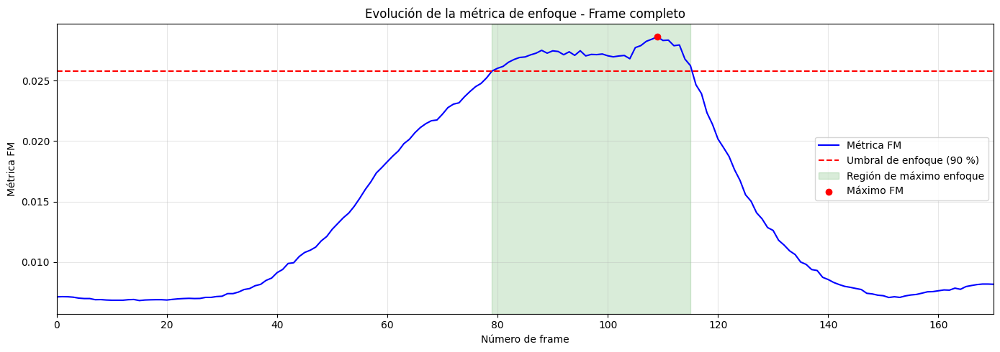

In [8]:

# Apertura del video
captura = cv.VideoCapture(ruta)

metricas_completo = []

# Cálculo de FM para cada frame completo
while True:
    ret, frame = captura.read()

    if not ret:
        break

    gris = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    FM = metrica_enfoque(gris)
    metricas_completo.append(FM)

captura.release()

metricas_completo = np.array(metricas_completo)
indices_completo = np.arange(len(metricas_completo))

# Detección automática de la región de máximo enfoque
maximo_completo, inicio_completo, fin_completo, umbral_completo = detectar_region_enfoque(metricas_completo)

cantidad_completo = fin_completo - inicio_completo + 1
duracion_completo = cantidad_completo / fps

# Resultados
print(f'Frames analizados: {len(metricas_completo)}')
print(f'Frame de máximo enfoque: {maximo_completo}')
print(f'Tiempo de máximo enfoque: {maximo_completo / fps:.2f} s')
print(f'Métrica máxima: {metricas_completo[maximo_completo]:.6f}')
print(f'Umbral de enfoque: {umbral_completo:.6f}')
print(f'Región de máximo enfoque: Frames {inicio_completo} a {fin_completo}')
print(f'Cantidad de frames enfocados: {cantidad_completo}')
print(f'Duración de la región de enfoque: {duracion_completo:.2f} s')

# Evolución de la métrica de enfoque
plt.figure(figsize=(14, 5))

plt.plot(indices_completo, metricas_completo,
         color='blue', label='Métrica FM')

plt.axhline(umbral_completo, color='red', linestyle='--',
            label='Umbral de enfoque (90 %)')

plt.axvspan(inicio_completo, fin_completo, color='green',
            alpha=0.15, label='Región de máximo enfoque')

plt.scatter(maximo_completo, metricas_completo[maximo_completo],
            color='red', zorder=5, label='Máximo FM')

plt.title('Evolución de la métrica de enfoque - Frame completo')
plt.xlabel('Número de frame')
plt.ylabel('Métrica FM')
plt.xlim(0, len(metricas_completo) - 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Observaciones:**

- La métrica presenta valores bajos al inicio del video, aumenta progresivamente hasta alcanzar una región de mayor enfoque y posteriormente disminuye a medida que la imagen vuelve a desenfocarse.
- El máximo valor de FM es de 0.028624 y se obtiene en el frame 109, correspondiente a los 3.64 segundos del video.
- Con un umbral de 0.025762, el algoritmo identifica automáticamente una región de máximo enfoque comprendida entre los frames 79 y 115, con una duración de 1.23 segundos.
- Las pequeñas variaciones de FM dentro de esta región justifican el uso de un umbral en lugar de considerar únicamente el frame de mayor valor.
- La medición sobre el frame completo considera tanto los detalles del objeto como las texturas del fondo. El siguiente experimento permitirá evaluar la influencia de estos elementos mediante el análisis de una ROI central.

### 1.6 Experimento 2: ROI central

Se aplica la métrica FM sobre una región de interés (ROI) ubicada en el centro de cada frame, cuya área corresponde aproximadamente al 10 % del área total. La consigna mencionaba 5% o 10%.

En ese sentido, se selecciona 10% para disponer de una mayor cantidad de información de la región central y se mantiene una proporción similar a la del frame original.

Al igual que en el experimento anterior, se grafica la evolución de la métrica y se determina automáticamente la región de máximo enfoque utilizando el mismo criterio de detección.

Dimensiones de la ROI: 202 x 114 píxeles
Área respecto al frame: 9.99 %
Frames analizados: 171
Frame de máximo enfoque: 111
Tiempo de máximo enfoque: 3.70 s
Métrica máxima: 0.359389
Umbral de enfoque: 0.323450
Región de máximo enfoque: Frames 105 a 113
Cantidad de frames enfocados: 9
Duración de la región de enfoque: 0.30 s


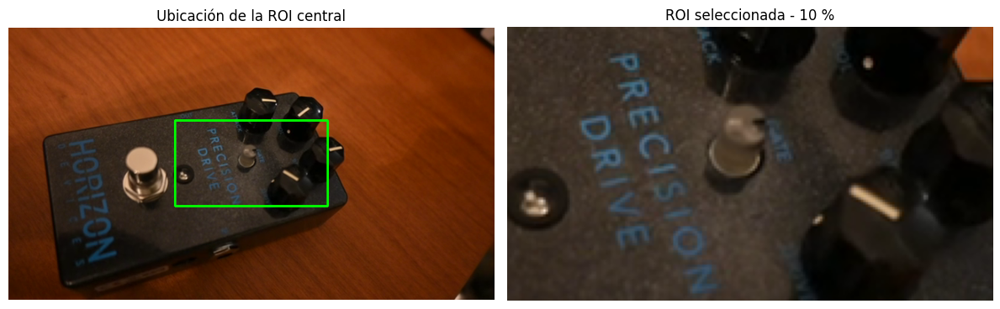

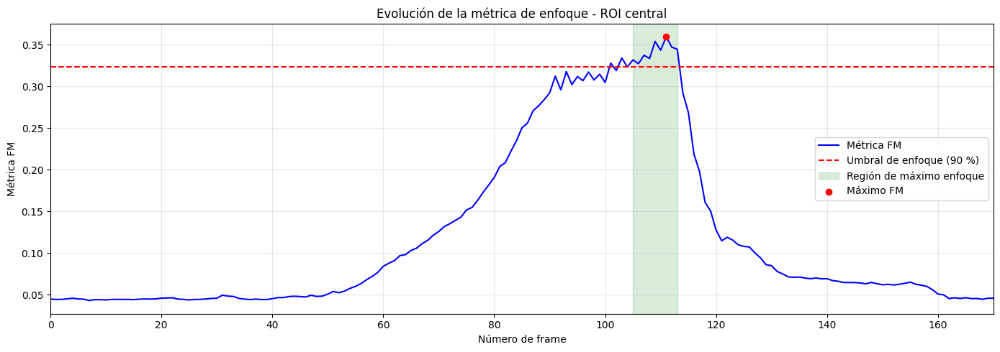

In [10]:
# Dimensiones de la ROI central
porcentaje_roi = 10
factor = np.sqrt(porcentaje_roi / 100)

ancho_roi = 2 * round(ancho * factor / 2)
alto_roi = 2 * round(alto * factor / 2)

# Coordenadas de la ROI
x1 = (ancho - ancho_roi) // 2
y1 = (alto - alto_roi) // 2
x2 = x1 + ancho_roi
y2 = y1 + alto_roi

area_roi = ancho_roi * alto_roi
porcentaje_real = 100 * area_roi / (ancho * alto)

# Apertura del video
captura = cv.VideoCapture(ruta)

metricas_roi = []

# Cálculo de FM sobre la ROI de cada frame
while True:
    ret, frame = captura.read()

    if not ret:
        break

    gris = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    roi = gris[y1:y2, x1:x2]

    FM = metrica_enfoque(roi)
    metricas_roi.append(FM)

captura.release()

metricas_roi = np.array(metricas_roi)
indices_roi = np.arange(len(metricas_roi))

# Detección automática de la región de máximo enfoque
maximo_roi, inicio_roi, fin_roi, umbral_roi = detectar_region_enfoque(metricas_roi)

cantidad_roi = fin_roi - inicio_roi + 1
duracion_roi = cantidad_roi / fps

# Resultados
print(f'Dimensiones de la ROI: {ancho_roi} x {alto_roi} píxeles')
print(f'Área respecto al frame: {porcentaje_real:.2f} %')
print(f'Frames analizados: {len(metricas_roi)}')
print(f'Frame de máximo enfoque: {maximo_roi}')
print(f'Tiempo de máximo enfoque: {maximo_roi / fps:.2f} s')
print(f'Métrica máxima: {metricas_roi[maximo_roi]:.6f}')
print(f'Umbral de enfoque: {umbral_roi:.6f}')
print(f'Región de máximo enfoque: Frames {inicio_roi} a {fin_roi}')
print(f'Cantidad de frames enfocados: {cantidad_roi}')
print(f'Duración de la región de enfoque: {duracion_roi:.2f} s')

# Visualización de la ROI sobre el frame intermedio
frame_roi = frames_muestra[total_frames // 2].copy()

cv.rectangle(frame_roi, (x1, y1), (x2 - 1, y2 - 1),
             (0, 255, 0), 2)

roi_muestra = frames_muestra[total_frames // 2][y1:y2, x1:x2]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(cv.cvtColor(frame_roi, cv.COLOR_BGR2RGB))
axes[0].set_title('Ubicación de la ROI central')
axes[0].axis('off')

axes[1].imshow(cv.cvtColor(roi_muestra, cv.COLOR_BGR2RGB))
axes[1].set_title('ROI seleccionada - 10 %')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Evolución de la métrica de enfoque
plt.figure(figsize=(14, 5))

plt.plot(indices_roi, metricas_roi,
         color='blue', label='Métrica FM')

plt.axhline(umbral_roi, color='red', linestyle='--',
            label='Umbral de enfoque (90 %)')

plt.axvspan(inicio_roi, fin_roi, color='green',
            alpha=0.15, label='Región de máximo enfoque')

plt.scatter(maximo_roi, metricas_roi[maximo_roi],
            color='red', zorder=5, label='Máximo FM')

plt.title('Evolución de la métrica de enfoque - ROI central')
plt.xlabel('Número de frame')
plt.ylabel('Métrica FM')
plt.xlim(0, len(metricas_roi) - 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Observaciones:**

- La ROI seleccionada tiene dimensiones de 202 × 114 píxeles, lo que representa el 9.99 % del área total del frame y cumple con lo solicitado en la consigna.
- La región seleccionada contiene letras, bordes y texturas del objeto, reduciendo la influencia del fondo en la medición.
- El máximo valor de FM es de 0.359389 y se obtiene en el frame 111, correspondiente a los 3.70 segundos del video.
- Con un umbral de 0.323450, se obtiene una región de máximo enfoque comprendida entre los frames 105 y 113, con una duración de 0.30 segundos.
- Se observan mayores fluctuaciones de la métrica cerca del máximo, lo que muestra una mayor sensibilidad a las variaciones del contenido espectral de la región seleccionada.

### 1.7 Comparación y análisis de los resultados

Se comparan los resultados obtenidos en los dos experimentos considerando el frame de máximo enfoque, los límites de la región detectada y su duración.

Para comparar la evolución de ambas métricas, se normalizan sus valores respecto al máximo de cada experimento. De esta manera, se utiliza una misma escala de valores sin modificar las mediciones originales.

Finalmente, se visualizan los frames correspondientes al inicio, al máximo y al final de las regiones de enfoque detectadas para complementar el análisis numérico y gráfico.

Característica                       Frame completo        ROI central
----------------------------------------------------------------------
Métrica máxima                             0.028624           0.359389
Umbral de enfoque                          0.025762           0.323450
Frame de máximo enfoque                         109                111
Tiempo de máximo enfoque (s)                   3.64               3.70
Inicio de la región                              79                105
Final de la región                              115                113
Cantidad de frames enfocados                     37                  9
Duración de la región (s)                      1.23               0.30


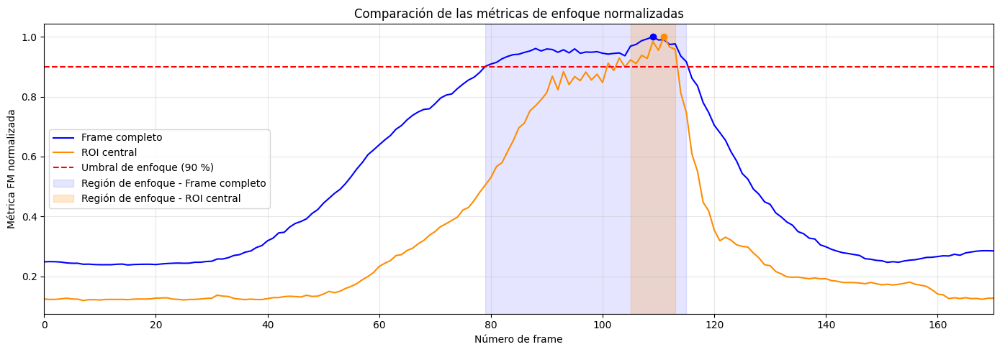

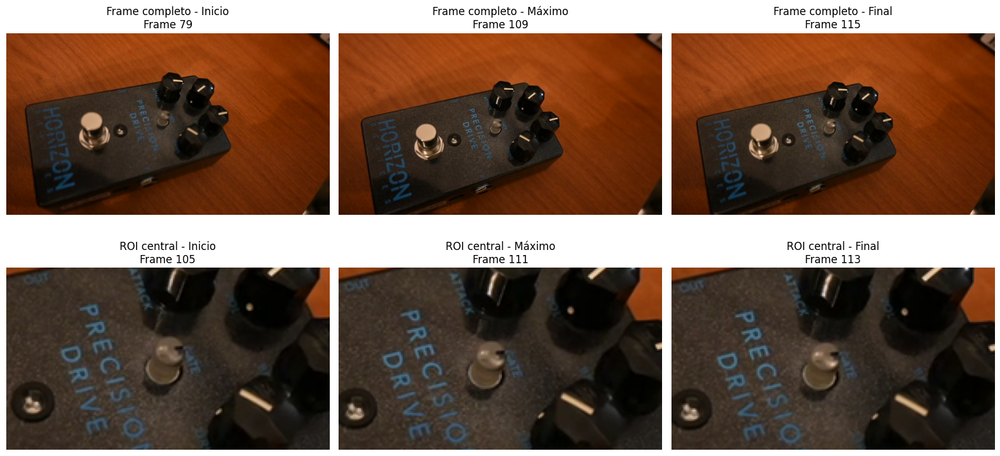

In [13]:
# Comparación numérica de los experimentos
print(f'{"Característica":<32} {"Frame completo":>18} {"ROI central":>18}')
print('-' * 70)

print(f'{"Métrica máxima":<32} {metricas_completo[maximo_completo]:>18.6f} {metricas_roi[maximo_roi]:>18.6f}')
print(f'{"Umbral de enfoque":<32} {umbral_completo:>18.6f} {umbral_roi:>18.6f}')
print(f'{"Frame de máximo enfoque":<32} {maximo_completo:>18} {maximo_roi:>18}')
print(f'{"Tiempo de máximo enfoque (s)":<32} {maximo_completo / fps:>18.2f} {maximo_roi / fps:>18.2f}')
print(f'{"Inicio de la región":<32} {inicio_completo:>18} {inicio_roi:>18}')
print(f'{"Final de la región":<32} {fin_completo:>18} {fin_roi:>18}')
print(f'{"Cantidad de frames enfocados":<32} {cantidad_completo:>18} {cantidad_roi:>18}')
print(f'{"Duración de la región (s)":<32} {duracion_completo:>18.2f} {duracion_roi:>18.2f}')

# Normalización respecto al máximo de cada experimento
metricas_completo_norm = metricas_completo / np.max(metricas_completo)
metricas_roi_norm = metricas_roi / np.max(metricas_roi)

# Comparación gráfica
plt.figure(figsize=(14, 5))

plt.plot(indices_completo, metricas_completo_norm,
         color='blue', label='Frame completo')

plt.plot(indices_roi, metricas_roi_norm,
         color='darkorange', label='ROI central')

plt.axhline(0.90, color='red', linestyle='--',
            label='Umbral de enfoque (90 %)')

plt.axvspan(inicio_completo, fin_completo, color='blue',
            alpha=0.10, label='Región de enfoque - Frame completo')

plt.axvspan(inicio_roi, fin_roi, color='darkorange',
            alpha=0.20, label='Región de enfoque - ROI central')

plt.scatter(maximo_completo, metricas_completo_norm[maximo_completo],
            color='blue', zorder=5)

plt.scatter(maximo_roi, metricas_roi_norm[maximo_roi],
            color='darkorange', zorder=5)

plt.title('Comparación de las métricas de enfoque normalizadas')
plt.xlabel('Número de frame')
plt.ylabel('Métrica FM normalizada')
plt.xlim(0, len(metricas_completo) - 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Selección de frames para la comparación visual
indices_comparacion = [inicio_completo, maximo_completo, fin_completo,
                       inicio_roi, maximo_roi, fin_roi]

frames_comparacion = {}

captura = cv.VideoCapture(ruta)

i = 0

while True:
    ret, frame = captura.read()

    if not ret:
        break

    if i in indices_comparacion:
        frames_comparacion[i] = frame.copy()

    i += 1

captura.release()

# Visualización de las regiones de máximo enfoque
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

titulos = ['Inicio', 'Máximo', 'Final']

for j in range(3):

    # Frames correspondientes al primer experimento
    indice = indices_comparacion[j]
    frame = frames_comparacion[indice]

    axes[0, j].imshow(cv.cvtColor(frame, cv.COLOR_BGR2RGB))
    axes[0, j].set_title(f'Frame completo - {titulos[j]}\nFrame {indice}')
    axes[0, j].axis('off')

    # ROI correspondientes al segundo experimento
    indice = indices_comparacion[j + 3]
    frame = frames_comparacion[indice]

    roi = frame[y1:y2, x1:x2]

    axes[1, j].imshow(cv.cvtColor(roi, cv.COLOR_BGR2RGB))
    axes[1, j].set_title(f'ROI central - {titulos[j]}\nFrame {indice}')
    axes[1, j].axis('off')

plt.tight_layout()
plt.show()


**Observaciones:**

- Ambas curvas presentan un comportamiento similar a lo largo del video, alcanzando sus valores máximos en los frames 109 y 111, respectivamente.
- La región de enfoque obtenida mediante la ROI central se encuentra completamente dentro de la región detectada utilizando el frame completo.
- La medición sobre el frame completo identifica 37 frames enfocados, mientras que la ROI central identifica 9, mostrando una mayor variación relativa de FM en la región seleccionada.
- Los valores absolutos de FM no son directamente comparables debido a las diferencias de dimensiones y contenido espectral de las regiones analizadas. La normalización permite comparar su evolución respecto a sus propios máximos.
- La comparación visual permite apreciar que las diferencias de enfoque entre los frames seleccionados son pequeñas, lo que demuestra la utilidad de la métrica para detectar variaciones difíciles de distinguir a simple vista.

### Conclusiones de la Parte 1

- El análisis mediante la transformada de Fourier permitió observar la relación entre el enfoque de una imagen y sus componentes de alta frecuencia, lo que justifica el uso de la métrica FM.
- La métrica propuesta en el paper permitió identificar los cambios de enfoque a lo largo del video en ambos experimentos.
- El uso de un umbral del 90 % respecto al valor máximo de FM permitió detectar una región continua de enfoque y no solamente el frame con mayor valor de la métrica.
- El área sobre la que se realiza la medición influye en los resultados. El frame completo considera toda la escena, mientras que la ROI permite evaluar el enfoque en una zona específica del objeto.
- La elección entre ambos métodos dependerá de la aplicación y de si se busca evaluar el enfoque de toda la imagen o únicamente el de una región de interés.

## 2. Ampliación de la región de enfoque

### 2.1 Implementación de Unsharp Masking

Se implementa la técnica unsharp masking, cuyo objetivo es realzar las componentes de alta frecuencia de una imagen.

El algoritmo consiste en los siguientes pasos:

1. Aplicar un filtro gaussiano sobre la imagen original $f(x,y)$ para obtener una imagen suavizada $f_B(x,y)$.
2. Obtener una máscara mediante la resta de ambas imágenes:

   $$m(x,y) = f(x,y) - f_B(x,y)$$

3. Sumar la máscara a la imagen original utilizando un factor de realce $k$:

   $$g(x,y) = f(x,y) + k \cdot m(x,y)$$

De manera equivalente, se obtiene la siguiente expresión:

$$g(x,y) = (k+1) \cdot f(x,y) - k \cdot f_B(x,y)$$

Se utilizan los valores de $k=1$ y $k=2.5$, junto con los parámetros del filtro gaussiano.

Se realiza una primera prueba sobre los frames inmediatamente anterior y posterior a la región de enfoque detectada en el primer experimento, para evaluar el efecto de ambos valores de $k$.

   Frame       Original          k = 1        k = 2.5
------------------------------------------------------
      78       0.025221       0.026593       0.029115
     116       0.024657       0.026107       0.028181


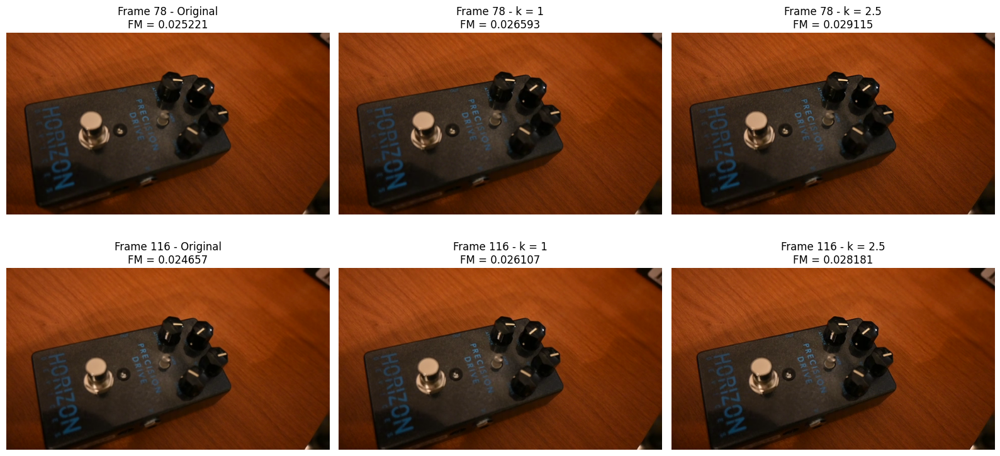

In [14]:

# Implementación de Unsharp Masking
def unsharp_masking(imagen, k):

    # Suavizado gaussiano
    gauss = cv.GaussianBlur(imagen, (7, 7), 0.5)

    # Realce de las componentes de alta frecuencia
    imagen_sharp = cv.addWeighted(imagen, k + 1, gauss, -k, 0)

    return imagen_sharp

# Selección de frames cercanos a la región de enfoque
indices_prueba = [inicio_completo - 1, fin_completo + 1]
frames_prueba = {}

captura = cv.VideoCapture(ruta)

i = 0

while True:
    ret, frame = captura.read()

    if not ret:
        break

    if i in indices_prueba:
        frames_prueba[i] = frame.copy()

    i += 1

captura.release()

# Valores de k utilizados en la prueba
valores_k = [1, 2.5]

# Comparación visual y numérica
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

print(f'{"Frame":>8} {"Original":>14} {"k = 1":>14} {"k = 2.5":>14}')
print('-' * 54)

for j, indice in enumerate(indices_prueba):

    frame = frames_prueba[indice]

    gris = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    FM_original = metrica_enfoque(gris)

    # Visualización del frame original
    axes[j, 0].imshow(cv.cvtColor(frame, cv.COLOR_BGR2RGB))
    axes[j, 0].set_title(f'Frame {indice} - Original\nFM = {FM_original:.6f}')
    axes[j, 0].axis('off')

    metricas_prueba_sharp = []

    for l, k in enumerate(valores_k):

        # Aplicación de Unsharp Masking
        frame_sharp = unsharp_masking(frame, k)

        # Cálculo de la métrica de enfoque
        gris_sharp = cv.cvtColor(frame_sharp, cv.COLOR_BGR2GRAY)
        FM_sharp = metrica_enfoque(gris_sharp)

        metricas_prueba_sharp.append(FM_sharp)

        # Visualización del frame procesado
        axes[j, l + 1].imshow(cv.cvtColor(frame_sharp, cv.COLOR_BGR2RGB))
        axes[j, l + 1].set_title(f'Frame {indice} - k = {k}\nFM = {FM_sharp:.6f}')
        axes[j, l + 1].axis('off')

    print(f'{indice:>8} {FM_original:>14.6f} {metricas_prueba_sharp[0]:>14.6f} {metricas_prueba_sharp[1]:>14.6f}')

plt.tight_layout()
plt.show()


**Observaciones:**

- La aplicación de Unsharp Masking incrementa el valor de FM en ambos frames, siendo mayor el incremento para k = 2.5.
- Con ambos valores de k, los frames procesados superan el umbral de enfoque obtenido en el primer experimento, lo que indica la posibilidad de ampliar la región de enfoque.
- Visualmente, se aprecia un mayor realce de los bordes del objeto y de la textura del fondo, sin cambios pronunciados en la imagen.
- Si bien un mayor valor de k aumenta la métrica FM, también puede amplificar el ruido. Por ello, es importante complementar la medición con una evaluación visual.

### 2.2 Aplicación sobre las regiones de transición

Se aplica Unsharp Masking sobre los frames anteriores y posteriores a la región de máximo enfoque obtenida en el primer experimento.

Para delimitar las regiones de transición, se consideran los frames consecutivos cuya métrica FM se encuentra entre el 80 % y el 90 % del valor máximo original. Se establece este criterio para procesar únicamente los frames cercanos a la región de enfoque.

De acuerdo con los resultados de la sección anterior, se utiliza un valor de $k=2.5$.

Se calcula nuevamente la métrica FM de los frames procesados y se conservan sin modificaciones los demás frames del video.

Factor de realce k: 2.5
Umbral de transición (80 %): 0.022899
Umbral de enfoque (90 %): 0.025762
Región de transición anterior: Frames 72 a 78
Región de transición posterior: Frames 116 a 117
Cantidad de frames procesados: 9

   Frame     FM original    FM procesada
------------------------------------------
      72        0.023056        0.025564
      73        0.023164        0.026055
      74        0.023668        0.026654
      75        0.024102        0.027513
      76        0.024497        0.027943
      77        0.024766        0.028598
      78        0.025221        0.029115
     116        0.024657        0.028181
     117        0.023928        0.027079


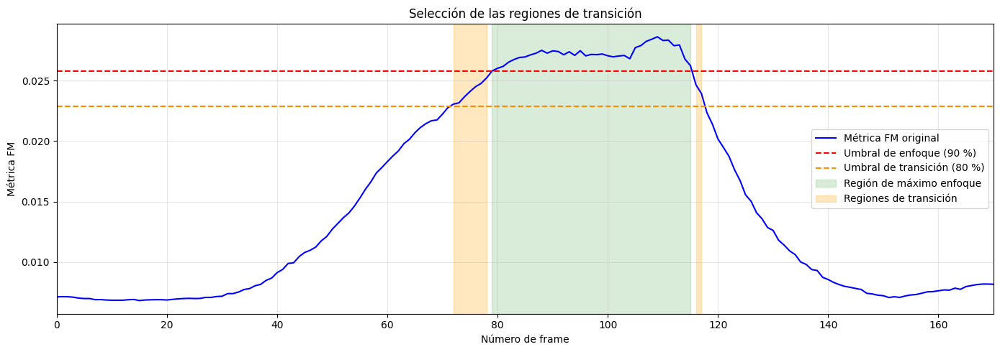

In [15]:

# Parámetros de procesamiento
k = 2.5
umbral_transicion = 0.80 * metricas_completo[maximo_completo]

# Detección de la región de transición anterior
inicio_transicion = inicio_completo

while inicio_transicion > 0 and metricas_completo[inicio_transicion - 1] >= umbral_transicion:
    inicio_transicion -= 1

# Detección de la región de transición posterior
fin_transicion = fin_completo

while fin_transicion < len(metricas_completo) - 1 and metricas_completo[fin_transicion + 1] >= umbral_transicion:
    fin_transicion += 1

# Selección de los frames a procesar
indices_transicion = list(range(inicio_transicion, inicio_completo))
indices_transicion += list(range(fin_completo + 1, fin_transicion + 1))

# Conservación de las métricas originales
metricas_sharp = metricas_completo.copy()
frames_procesados = {}

# Apertura del video
captura = cv.VideoCapture(ruta)

i = 0

while True:
    ret, frame = captura.read()

    if not ret:
        break

    if i in indices_transicion:

        # Aplicación de Unsharp Masking
        frame_sharp = unsharp_masking(frame, k)
        frames_procesados[i] = frame_sharp

        # Cálculo de la métrica de enfoque
        gris_sharp = cv.cvtColor(frame_sharp, cv.COLOR_BGR2GRAY)
        metricas_sharp[i] = metrica_enfoque(gris_sharp)

    i += 1

captura.release()

# Resultados del procesamiento
print(f'Factor de realce k: {k}')
print(f'Umbral de transición (80 %): {umbral_transicion:.6f}')
print(f'Umbral de enfoque (90 %): {umbral_completo:.6f}')
print(f'Región de transición anterior: Frames {inicio_transicion} a {inicio_completo - 1}')
print(f'Región de transición posterior: Frames {fin_completo + 1} a {fin_transicion}')
print(f'Cantidad de frames procesados: {len(frames_procesados)}')
print()

# Visualización de los resultados numéricos
print(f'{"Frame":>8} {"FM original":>15} {"FM procesada":>15}')
print('-' * 42)

for indice in indices_transicion:

    print(f'{indice:>8} {metricas_completo[indice]:>15.6f} {metricas_sharp[indice]:>15.6f}')

# Visualización de las regiones de transición
plt.figure(figsize=(14, 5))

plt.plot(indices_completo, metricas_completo,
         color='blue', label='Métrica FM original')

plt.axhline(umbral_completo, color='red', linestyle='--',
            label='Umbral de enfoque (90 %)')

plt.axhline(umbral_transicion, color='darkorange', linestyle='--',
            label='Umbral de transición (80 %)')

plt.axvspan(inicio_completo, fin_completo, color='green',
            alpha=0.15, label='Región de máximo enfoque')

plt.axvspan(inicio_transicion, inicio_completo - 1,
            color='orange', alpha=0.25, label='Regiones de transición')

plt.axvspan(fin_completo + 1, fin_transicion,
            color='orange', alpha=0.25)

plt.title('Selección de las regiones de transición')
plt.xlabel('Número de frame')
plt.ylabel('Métrica FM')
plt.xlim(0, len(metricas_completo) - 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Observaciones:**

- El algoritmo identifica dos regiones de transición, comprendidas entre los frames 72 y 78 y entre los frames 116 y 117.
- La aplicación de Unsharp Masking incrementa el valor de FM en los nueve frames procesados.
- Ocho de los nueve frames superan el umbral original de enfoque, mientras que el frame 72 permanece ligeramente por debajo.
- Se observa que el incremento de FM no es uniforme, lo que indica que el efecto del realce depende del contenido espectral de cada frame.

### 2.3 Evaluación de la ampliación de la región de enfoque

Se compara la evolución de la métrica FM antes y después de aplicar Unsharp Masking.

Para evaluar la ampliación de la región de enfoque se mantiene el umbral obtenido en el primer experimento, de manera que ambas mediciones se comparen bajo las mismas condiciones.

Se calcula la cantidad de frames incorporados a la región de enfoque, el aumento de su duración y el porcentaje de ampliación obtenido.

Finalmente, se realiza una comparación visual de los frames correspondientes a los nuevos límites de la región de enfoque.

Característica                             Original    Unsharp Masking
----------------------------------------------------------------------
Métrica máxima                             0.028624           0.029115
Frame de máximo enfoque                         109                 78
Umbral de enfoque                          0.025762           0.025762
Inicio de la región                              79                 73
Final de la región                              115                117
Cantidad de frames enfocados                     37                 45
Duración de la región (s)                      1.23               1.50

Frames adicionales: 8
Aumento de la duración: 0.27 s
Ampliación de la región de enfoque: 21.62 %


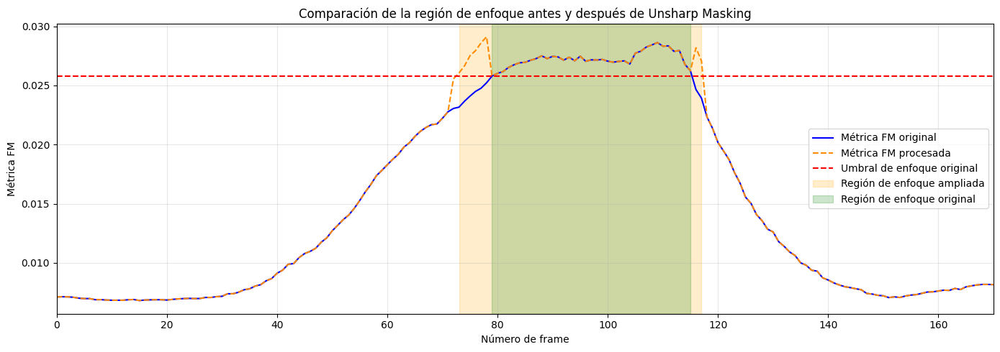

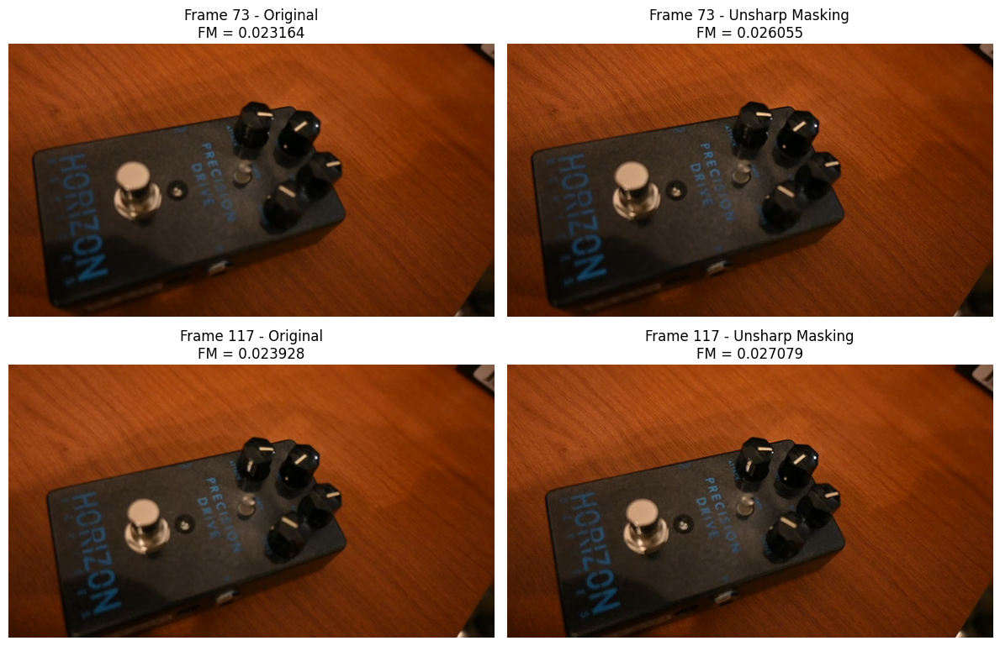

In [16]:

# Detección de la nueva región de enfoque
# Se mantiene el umbral original del primer experimento
inicio_sharp = inicio_completo
fin_sharp = fin_completo

while inicio_sharp > 0 and metricas_sharp[inicio_sharp - 1] >= umbral_completo:
    inicio_sharp -= 1

while fin_sharp < len(metricas_sharp) - 1 and metricas_sharp[fin_sharp + 1] >= umbral_completo:
    fin_sharp += 1

# Características de la nueva región de enfoque
cantidad_sharp = fin_sharp - inicio_sharp + 1
duracion_sharp = cantidad_sharp / fps

frames_adicionales = cantidad_sharp - cantidad_completo
duracion_adicional = duracion_sharp - duracion_completo
porcentaje_ampliacion = 100 * frames_adicionales / cantidad_completo

# Comparación numérica
print(f'{"Característica":<32} {"Original":>18} {"Unsharp Masking":>18}')
print('-' * 70)

print(f'{"Métrica máxima":<32} {np.max(metricas_completo):>18.6f} {np.max(metricas_sharp):>18.6f}')
print(f'{"Frame de máximo enfoque":<32} {maximo_completo:>18} {np.argmax(metricas_sharp):>18}')
print(f'{"Umbral de enfoque":<32} {umbral_completo:>18.6f} {umbral_completo:>18.6f}')
print(f'{"Inicio de la región":<32} {inicio_completo:>18} {inicio_sharp:>18}')
print(f'{"Final de la región":<32} {fin_completo:>18} {fin_sharp:>18}')
print(f'{"Cantidad de frames enfocados":<32} {cantidad_completo:>18} {cantidad_sharp:>18}')
print(f'{"Duración de la región (s)":<32} {duracion_completo:>18.2f} {duracion_sharp:>18.2f}')

print()
print(f'Frames adicionales: {frames_adicionales}')
print(f'Aumento de la duración: {duracion_adicional:.2f} s')
print(f'Ampliación de la región de enfoque: {porcentaje_ampliacion:.2f} %')

# Comparación gráfica de las métricas
plt.figure(figsize=(14, 5))

plt.plot(indices_completo, metricas_completo,
         color='blue', label='Métrica FM original')

plt.plot(indices_completo, metricas_sharp,
         color='darkorange', linestyle='--',
         label='Métrica FM procesada')

plt.axhline(umbral_completo, color='red', linestyle='--',
            label='Umbral de enfoque original')

plt.axvspan(inicio_sharp, fin_sharp, color='orange',
            alpha=0.20, label='Región de enfoque ampliada')

plt.axvspan(inicio_completo, fin_completo, color='green',
            alpha=0.20, label='Región de enfoque original')

plt.title('Comparación de la región de enfoque antes y después de Unsharp Masking')
plt.xlabel('Número de frame')
plt.ylabel('Métrica FM')
plt.xlim(0, len(metricas_completo) - 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Selección de los frames correspondientes a los nuevos límites
indices_limites = [inicio_sharp, fin_sharp]
frames_limites = {}

captura = cv.VideoCapture(ruta)

i = 0

while True:
    ret, frame = captura.read()

    if not ret:
        break

    if i in indices_limites:
        frames_limites[i] = frame.copy()

    i += 1

captura.release()

# Comparación visual antes y después del procesamiento
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for j, indice in enumerate(indices_limites):

    frame_original = frames_limites[indice]
    frame_sharp = frames_procesados.get(indice, frame_original)

    axes[j, 0].imshow(cv.cvtColor(frame_original, cv.COLOR_BGR2RGB))
    axes[j, 0].set_title(f'Frame {indice} - Original\nFM = {metricas_completo[indice]:.6f}')
    axes[j, 0].axis('off')

    axes[j, 1].imshow(cv.cvtColor(frame_sharp, cv.COLOR_BGR2RGB))
    axes[j, 1].set_title(f'Frame {indice} - Unsharp Masking\nFM = {metricas_sharp[indice]:.6f}')
    axes[j, 1].axis('off')

plt.tight_layout()
plt.show()


**Observaciones:**

- La región de enfoque se amplía de 37 a 45 frames, aumentando su duración de 1.23 a 1.50 segundos.
- Se incorporan seis frames al inicio de la región y dos al final, obteniendo una ampliación del 21.62 % respecto a la región original.
- El máximo valor de FM pasa del frame 109 al frame 78 como resultado del realce aplicado.
- Visualmente, se aprecia un ligero realce de las texturas y algunos bordes, aunque las diferencias entre los frames originales y procesados son pequeñas.
- Si bien se consigue ampliar la región de enfoque según la métrica FM, esto no implica recuperar el enfoque óptico perdido durante la captura del video.

### 2.4 Generación y visualización del video resultante

Se genera un nuevo video utilizando los frames procesados mediante Unsharp Masking y los frames originales que no forman parte de las regiones de transición.

Se mantienen la resolución, la cantidad de frames y los FPS del video original. Finalmente, se visualiza el video resultante para evaluar el efecto del procesamiento a lo largo del tiempo.

In [18]:
from IPython.display import Video, display
from tempfile import TemporaryDirectory
import subprocess
import os

# Generación de los videos en archivos temporales
with TemporaryDirectory() as carpeta:

    ruta_temporal = os.path.join(carpeta, 'temporal.mp4')
    ruta_original_mp4 = os.path.join(carpeta, 'original.mp4')
    ruta_salida = os.path.join(carpeta, 'procesado.mp4')

    # Apertura del video original
    captura = cv.VideoCapture(ruta)

    # Configuración del video de salida
    fourcc = cv.VideoWriter_fourcc(*'mp4v')
    salida = cv.VideoWriter(ruta_temporal, fourcc, fps, (ancho, alto))

    if not salida.isOpened():
        captura.release()
        raise ValueError('No se pudo generar el video')

    # Generación del video procesado
    i = 0

    while True:
        ret, frame = captura.read()

        if not ret:
            break

        if i in frames_procesados:
            frame = frames_procesados[i]

        salida.write(frame)

        i += 1

    captura.release()
    salida.release()

    # Conversión del video procesado a H.264
    subprocess.run([
        'ffmpeg', '-y', '-loglevel', 'error',
        '-i', ruta_temporal,
        '-c:v', 'libx264', '-crf', '18',
        '-pix_fmt', 'yuv420p',
        ruta_salida
    ], check=True)

    # Copia del video original en formato MP4
    subprocess.run([
        'ffmpeg', '-y', '-loglevel', 'error',
        '-i', ruta,
        '-map', '0:v:0', '-map', '0:a?',
        '-c', 'copy',
        '-movflags', '+faststart',
        ruta_original_mp4
    ], check=True)

    # Verificación del video procesado
    captura = cv.VideoCapture(ruta_salida)

    ancho_salida = int(captura.get(cv.CAP_PROP_FRAME_WIDTH))
    alto_salida = int(captura.get(cv.CAP_PROP_FRAME_HEIGHT))
    fps_salida = captura.get(cv.CAP_PROP_FPS)
    total_salida = int(captura.get(cv.CAP_PROP_FRAME_COUNT))

    captura.release()

    # Almacenamiento de ambos videos en memoria
    with open(ruta_original_mp4, 'rb') as archivo:
        video_original = archivo.read()

    with open(ruta_salida, 'rb') as archivo:
        video_procesado = archivo.read()

# Características del video resultante
print(f'Resolución: {ancho_salida} x {alto_salida} píxeles')
print(f'FPS: {fps_salida:.2f}')
print(f'Total de frames: {total_salida}')
print(f'Duración: {total_salida / fps_salida:.2f} segundos')
print(f'Frames con Unsharp Masking: {len(frames_procesados)}')
print(f'Frames sin realce: {i - len(frames_procesados)}')

# Visualización del video original
print('\nVideo original:')
display(Video(data=video_original, embed=True,
              mimetype='video/mp4', width=640))

# Visualización del video procesado
print('\nVideo procesado:')
display(Video(data=video_procesado, embed=True,
              mimetype='video/mp4', width=640))


Resolución: 640 x 360 píxeles
FPS: 29.97
Total de frames: 171
Duración: 5.71 segundos
Frames con Unsharp Masking: 9
Frames sin realce: 162

Video original:



Video procesado:


**Análisis final en el dominio de la frecuencia**

Para complementar la comparación visual de los videos, se aplica la transformada de Fourier a todos los frames del video original y del video procesado.

Se calcula el espectro promedio de cada video y se grafica la diferencia entre ambos para observar los cambios producidos por Unsharp Masking.

Adicionalmente, se calcula el porcentaje de energía correspondiente a las altas frecuencias de cada frame. Para este análisis se consideran altas frecuencias aquellas iguales o superiores a 0.25 ciclos por píxel.

La comparación se realiza antes de la compresión del video resultante para evaluar únicamente el efecto del procesamiento aplicado.

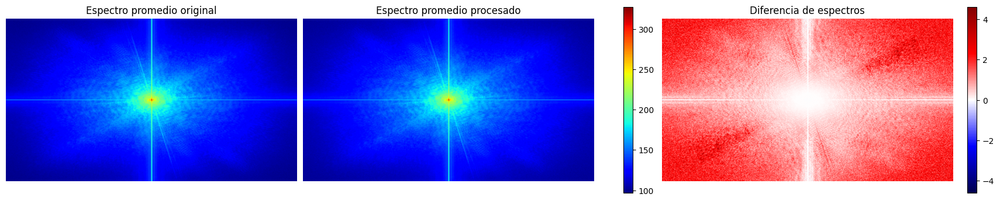

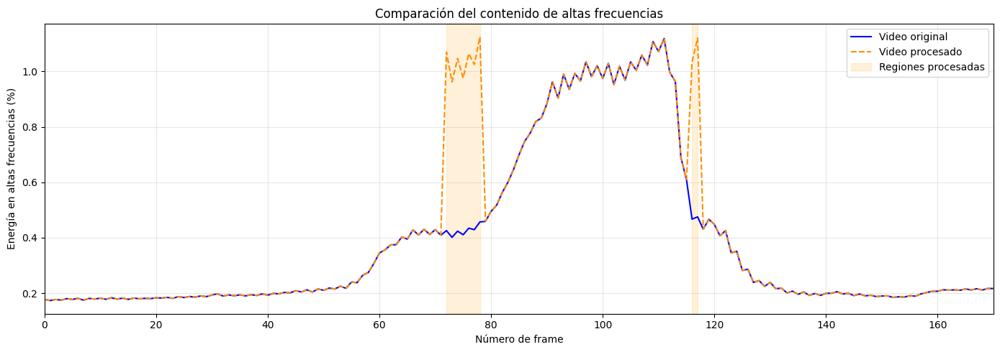

Frames analizados por video: 171
Contenido promedio de altas frecuencias:
Video original: 0.382452 %
Video procesado: 0.414619 %


In [19]:
# Frecuencias espaciales de los frames
fx = np.fft.fftshift(np.fft.fftfreq(ancho))
fy = np.fft.fftshift(np.fft.fftfreq(alto))

FX, FY = np.meshgrid(fx, fy)
frecuencias = np.sqrt(FX**2 + FY**2)

# Selección de las altas frecuencias
mascara_af = frecuencias >= 0.25

# Exclusión de la componente continua
mascara_ac = frecuencias > 0

# Función para analizar el contenido frecuencial de un frame
def analizar_frecuencias(frame):

    gris = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    fft = np.fft.fftshift(np.fft.fft2(gris))
    magnitud = np.abs(fft)

    # Cálculo de la energía espectral
    energia = magnitud**2

    energia_af = np.sum(energia[mascara_af])
    energia_total = np.sum(energia[mascara_ac])

    porcentaje_af = 100 * energia_af / energia_total if energia_total > 0 else 0

    return magnitud, porcentaje_af


# Inicialización de variables
suma_espectro_original = np.zeros((alto, ancho))
suma_espectro_procesado = np.zeros((alto, ancho))

altas_frecuencias_original = []
altas_frecuencias_procesado = []

# Apertura del video original
captura = cv.VideoCapture(ruta)

i = 0

while True:
    ret, frame = captura.read()

    if not ret:
        break

    # Obtención del frame procesado
    frame_sharp = frames_procesados.get(i, frame)

    # Análisis frecuencial de ambos frames
    magnitud_original, af_original = analizar_frecuencias(frame)
    magnitud_procesada, af_procesado = analizar_frecuencias(frame_sharp)

    # Acumulación de los espectros
    suma_espectro_original += magnitud_original
    suma_espectro_procesado += magnitud_procesada

    # Almacenamiento del contenido de altas frecuencias
    altas_frecuencias_original.append(af_original)
    altas_frecuencias_procesado.append(af_procesado)

    i += 1

captura.release()

# Cálculo de los espectros promedio en escala logarítmica
espectro_promedio_original = 20 * np.log(suma_espectro_original / i + 1)
espectro_promedio_procesado = 20 * np.log(suma_espectro_procesado / i + 1)

diferencia_espectros = espectro_promedio_procesado - espectro_promedio_original

# Escala común para ambos espectros
vmin = min(espectro_promedio_original.min(), espectro_promedio_procesado.min())
vmax = max(espectro_promedio_original.max(), espectro_promedio_procesado.max())

limite = max(np.max(np.abs(diferencia_espectros)), 1e-10)

# Visualización de los espectros promedio
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)

imagen_original = axes[0].imshow(
    espectro_promedio_original,
    cmap='jet', vmin=vmin, vmax=vmax
)

axes[0].set_title('Espectro promedio original')
axes[0].axis('off')

axes[1].imshow(
    espectro_promedio_procesado,
    cmap='jet', vmin=vmin, vmax=vmax
)

axes[1].set_title('Espectro promedio procesado')
axes[1].axis('off')

fig.colorbar(imagen_original, ax=axes[:2], shrink=0.65)

imagen_diferencia = axes[2].imshow(
    diferencia_espectros,
    cmap='seismic', vmin=-limite, vmax=limite
)

axes[2].set_title('Diferencia de espectros')
axes[2].axis('off')

fig.colorbar(imagen_diferencia, ax=axes[2], shrink=0.65)

plt.show()

# Comparación del contenido de altas frecuencias
plt.figure(figsize=(14, 5))

plt.plot(np.arange(i), altas_frecuencias_original,
         color='blue', label='Video original')

plt.plot(np.arange(i), altas_frecuencias_procesado,
         color='darkorange', linestyle='--',
         label='Video procesado')

plt.axvspan(inicio_transicion, inicio_completo - 1,
            color='orange', alpha=0.15,
            label='Regiones procesadas')

plt.axvspan(fin_completo + 1, fin_transicion,
            color='orange', alpha=0.15)

plt.title('Comparación del contenido de altas frecuencias')
plt.xlabel('Número de frame')
plt.ylabel('Energía en altas frecuencias (%)')
plt.xlim(0, i - 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Resultados numéricos
print(f'Frames analizados por video: {i}')
print(f'Contenido promedio de altas frecuencias:')
print(f'Video original: {np.mean(altas_frecuencias_original):.6f} %')
print(f'Video procesado: {np.mean(altas_frecuencias_procesado):.6f} %')


### Conclusiones de la Parte 2

- La aplicación de Unsharp Masking permitió ampliar la región de enfoque de 37 a 45 frames, obteniendo un incremento del 21.62 % respecto a la región original.

- El procesamiento se realizó únicamente sobre las regiones de transición, sin necesidad de aplicar el realce a todo el video.

- El análisis de Fourier permitió comprobar el incremento de las componentes de alta frecuencia en los frames procesados. El porcentaje promedio de energía en altas frecuencias pasó de 0.382452 % a 0.414619 %.

- Al reproducir ambos videos, las diferencias visuales son pequeñas. Esto resulta razonable considerando que solamente se procesaron 9 de los 171 frames.

- Unsharp Masking permitió mejorar la nitidez según la métrica utilizada y ampliar la región de enfoque, aunque presenta limitaciones para recuperar detalles perdidos durante la captura del video.